# M115 Lab 1: Phishing URL Detection — EDA, Parameterized Logistic Regression & SHAP Explainability

---

## 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027

---

## 🧭 Lab Overview & Solution Key

This notebook contains the assignment of **Lab 1** on the **[PhiUSIIL Phishing URL Dataset](https://www.kaggle.com/datasets/kaggleprollc/phishing-url-websites-dataset-phiusiil/data)** (*235,795 URLs and 56 lexical, network, and HTML features*, Prasad & Chandra, *Computers & Security*, 2024).

### 📋 Table of Contents
* **1 - Importing Packages & Loading Data**
* **2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)**
  * 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)
  * 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)
  * 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)
  * *Part 1 Reflection Questions*
* **3 - Part 2: Zero-Data Leakage Preprocessing & Standardization**
  * 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)
  * *Part 2 Reflection Questions*
* **4 - Part 3: Parameterized Logistic Regression & Interpretability**
  * 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)
  * 4.2 L1 Regularization Path & Feature Selection (Exercise 6)
  * 4.3 Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)
  * *Part 3 Reflection Questions*
* **5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis**
  * 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)
  * 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)
  * 5.3 Operational Decision Threshold Tuning ($\tau \in \{0.20, 0.50, 0.85\}$) (Exercise 10)
  * *Part 4 Reflection Questions*
* **6 - Conclusion & SOC Engineering Synthesis**

---
## 1 - Importing Packages & Loading Data

Run the cell below to import the required libraries and configure reproducibility (`SEED = 42`):

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score
)     
import shap                                                    

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 4.5)
SEED = 42
np.random.seed(SEED)

/home/imorig/.local/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
## 2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)

### 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)

First, we load `PhiUSIIL_Phishing_URL_Dataset.csv` and inspect its shape, data types, missing values, duplicate rows, and summary statistics across key numerical features (`URLLength`, `LineOfCode`, `CharContinuationRate`, `NoOfSelfRef`).

In [5]:
# Load dataset and inspect data quality
file_path = 'Lab1/PhiUSIIL_Phishing_URL_Dataset.csv'

df = pd.read_csv(file_path)
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("\nDataset Info:")
df.info()

display(df[['FILENAME', 'URL', 'URLLength', 'LineOfCode', 'IsHTTPS', 'HasPasswordField', 'NoOfSelfRef', 'label']].head(5))
display(df[['URLLength', 'LineOfCode', 'CharContinuationRate', 'NoOfSelfRef']].describe().round(2))

Dataset Shape: (235795, 56)
Total Missing Values: 0
Duplicate Rows: 0

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  

,FILENAME,URL,URLLength,LineOfCode,IsHTTPS,HasPasswordField,NoOfSelfRef,label
0,521848.txt,https://www.southbankmosaics.com,31,558,1,0,119,1
1,31372.txt,https://www.uni-mainz.de,23,618,1,0,39,1
2,597387.txt,https://www.voicefmradio.co.uk,29,467,1,0,42,1
3,554095.txt,https://www.sfnmjournal.com,26,6356,1,0,22,1
4,151578.txt,https://www.rewildingargentina.org,33,6089,1,0,72,1


,URLLength,LineOfCode,CharContinuationRate,NoOfSelfRef
count,235795.00,235795.00,235795.00,235795.00
mean,34.57,1141.90,0.85,65.07
std,41.31,3419.95,0.22,176.69
min,13.00,2.00,0.00,0.00
25%,23.00,18.00,0.68,0.00
50%,27.00,429.00,1.00,12.00
75%,34.00,1277.00,1.00,88.00
max,6097.00,442666.00,1.00,27397.00


> **⚠️ Critical Cyber Label Warning in PhiUSIIL:**  
> In the raw CSV file, **`label = 1` denotes Legitimate (Benign)** and **`label = 0` denotes Phishing (Malicious)**.  
> In a SOC, the positive class (`1`) **must always represent the attack** (`Phishing = 1`, `Benign = 0`) so that True Positives (TP), Precision, and Recall measure our threat detection capability.

### Exercise 1

In [ ]:
# Data Quality & SOC Target Alignment (1 = Phishing, 0 = Benign)

df['IsPhishing'] = 1-df['label']
phishing_ratio = df['IsPhishing'].mean()

print(f"Phishing URLs (1): {(df['IsPhishing'] == 1).sum():,}")
print(f"Legitimate URLs (0): {(df['IsPhishing'] == 0).sum():,}")
print(f"Phishing Proportion: {phishing_ratio * 100:.2f}%")
print("\nNormalized Class Proportions:")
print(df['IsPhishing'].value_counts(normalize=True).round(4))

Phishing URLs (1): 100,945
Legitimate URLs (0): 134,850
Phishing Proportion: 42.81%

Normalized Class Proportions:
IsPhishing
0    0.5719
1    0.4281
Name: proportion, dtype: float64


---
### 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)

We compare legitimate (`0`) and phishing (`1`) URLs across class balance, continuous lexical/HTML features (`URLLength`, `CharContinuationRate`, `NoOfSelfRef`), and binary security indicators (`IsHTTPS`, `HasPasswordField`, `HasCopyrightInfo`, `HasSocialNet`).

### Exercise 2

Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):


IsHTTPS             0.78
HasPasswordField    0.10
HasCopyrightInfo    0.49
HasSocialNet        0.46
dtype: float64

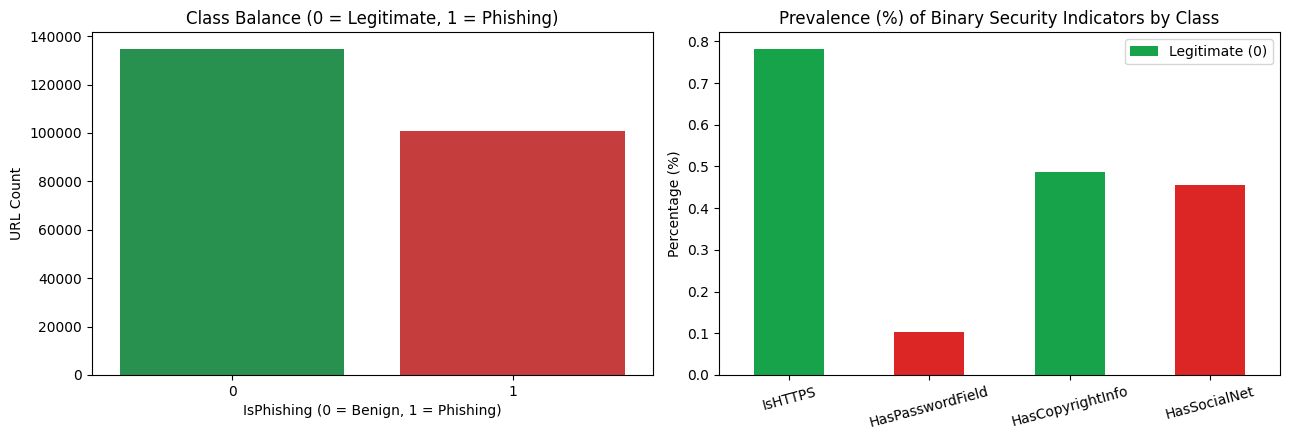

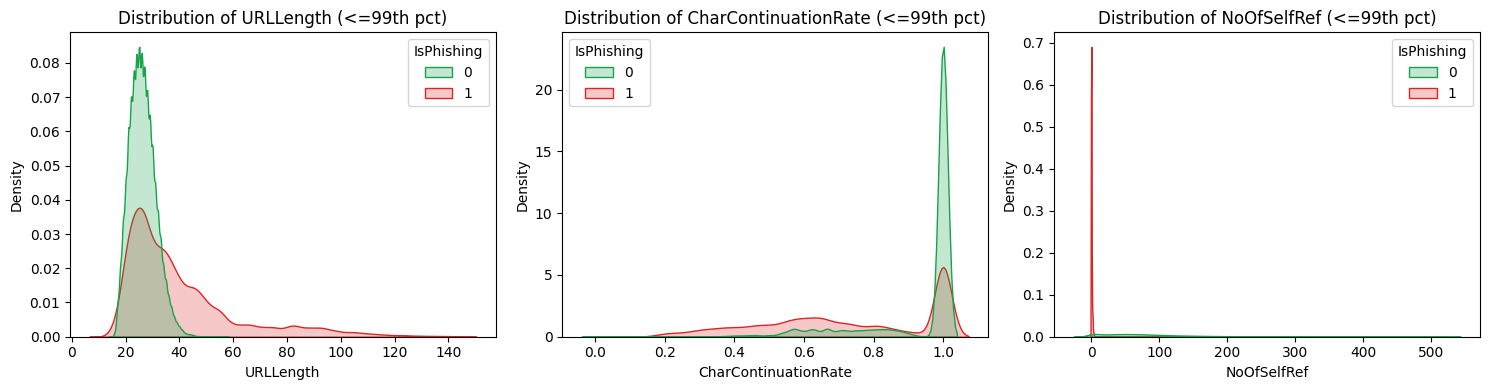

In [ ]:
# Visualizing Distributions and Binary Security Indicators
binary_cols = ['IsHTTPS', 'HasPasswordField', 'HasCopyrightInfo', 'HasSocialNet']
num_cols = ['URLLength', 'CharContinuationRate', 'NoOfSelfRef']

binary_stats = df[binary_cols].mean()

print("Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):")
display(binary_stats.round(2))

# 1. Class Balance & Binary Indicators Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x='IsPhishing', hue='IsPhishing', ax=axes[0], palette=['#16a34a', '#dc2626'], legend=False)
axes[0].set_title("Class Balance (0 = Legitimate, 1 = Phishing)")
axes[0].set_xlabel("IsPhishing (0 = Benign, 1 = Phishing)")
axes[0].set_ylabel("URL Count")

binary_stats.T.plot(kind='bar', ax=axes[1], color=['#16a34a', '#dc2626'])
axes[1].set_title("Prevalence (%) of Binary Security Indicators by Class")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xticklabels(binary_cols, rotation=15)
axes[1].legend(["Legitimate (0)", "Phishing (1)"])
plt.tight_layout()
plt.show()

# 2. Numerical Distributions (KDE Plots clipped at 99th percentile for readability)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(num_cols):
    upper_clip = df[col].quantile(0.99)
    sns.kdeplot(
        data=df[df[col] <= upper_clip],
        x=col,
        hue='IsPhishing',
        common_norm=False,
        fill=True,
        palette=['#16a34a', '#dc2626'],
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col} (<=99th pct)")
plt.tight_layout()
plt.show()

---
### 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)

We drop non-generalizable raw text strings (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`), the old `label`, and the pre-computed `URLSimilarityIndex` score so our model learns from genuine lexical and HTML indicators. Then we compute the Pearson correlation of each numerical feature with `IsPhishing`.

### Exercise 3

Shape of X: (235795, 49) | Shape of y: (235795,)


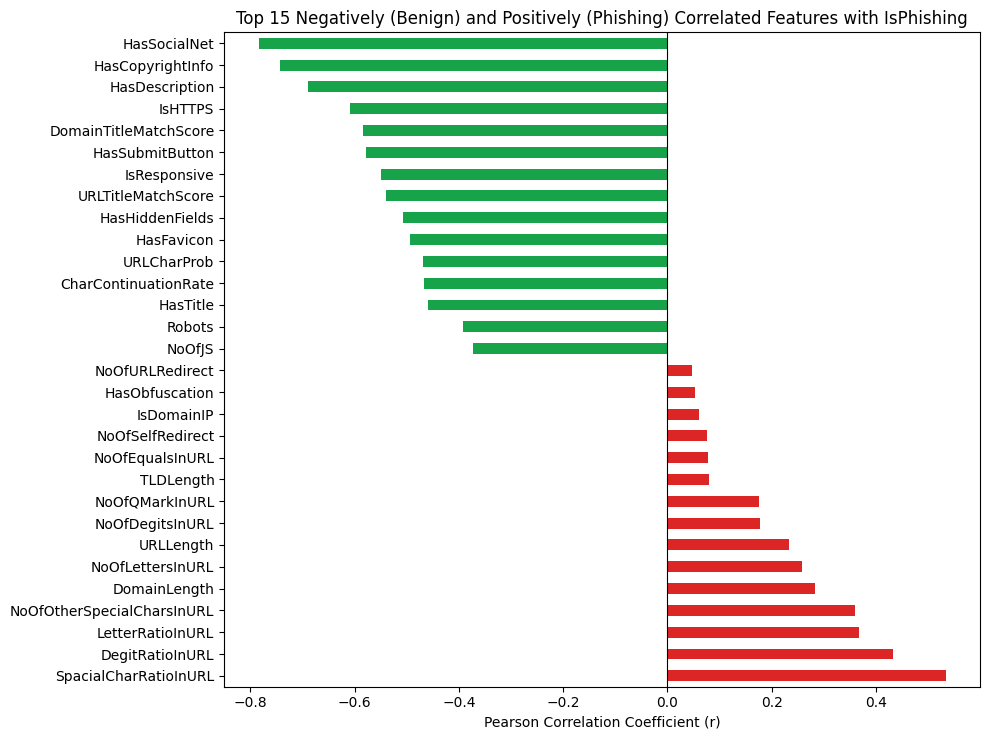

In [ ]:
# Constructing X, y and Analyzing Target Correlations
cols_to_drop = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label', 'IsPhishing', 'URLSimilarityIndex']

X = df.drop(columns=cols_to_drop)
y = df['IsPhishing']
correlations = X.corrwith(y).sort_values(ascending=False)

print("Shape of X:", X.shape, "| Shape of y:", y.shape)

# Plot Top 15 Negatively and Top 15 Positively Correlated Features
top_corr = pd.concat([correlations.head(15), correlations.tail(15)])
plt.figure(figsize=(10, 7.5))
colors = ['#16a34a' if c < 0 else '#dc2626' for c in top_corr.values]
top_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Top 15 Negatively (Benign) and Positively (Phishing) Correlated Features with IsPhishing")
plt.xlabel("Pearson Correlation Coefficient (r)")
plt.tight_layout()
plt.show()

---
### 💡 Part 1 Reflection Questions

1. **Looking at your plot for `IsHTTPS`, what percentage of phishing sites currently use an HTTPS certificate? Why is a static rule *"If HTTPS then Legitimate"* dangerous?**
   * **Answer:** Although HTTPS has negative correlation with phishing sites approximately -0.60, this does not mean that all HTTPS websites are legitimate. A sighificant proportion of websites can also use HTTPS certifcates, including free certificates from services such as Let's encrypt.

2. **Why do phishing websites typically have very few internal links (`NoOfSelfRef`) but very frequently contain a password field (`HasPasswordField`)?**
   * **Answer:** Phishing websites typically contain very few internal links because they are designed for a specific purpose, such as collecting user's credential, rather than providing a complet website fonctionality. However they contain frequently password fields because attakers aime to steal sensitive information.

3. **What would happen in production if we left the `FILENAME`, `URL`, or `Domain` column in our training matrix?**
   * **Answer:** Kepping the filename, URL or Domain columns could introduce data leakage or overfitting, the model might memorise filenames, specific domains, instead of learning mningful characteristics of phishing websites. Consecently it acheive very high accuracy during training and testing but perform poorly in production when encountering previously unseen URLs and Domains.

---
## 3 - Part 2: Zero-Data Leakage Preprocessing & Standardization

### 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)

We apply the **SecMLOps Golden Rule**: split the dataset into training (75%) and test (25%) subsets *before* computing Z-score normalization parameters ($\mu_{\text{train}}, \sigma_{\text{train}}$).

### Exercise 4

In [ ]:
# Stratified Split and Leakage-Free Standardization

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Retain column names and indices for weight and SHAP interpretability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("Train shape:", X_train_scaled.shape, "| Test shape:", X_test_scaled.shape)
print("Mean of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].mean(), 4))
print("Std of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].std(), 4))

Train shape: (176846, 49) | Test shape: (58949, 49)
Mean of X_train_scaled (URLLength): -0.0
Std of X_train_scaled (URLLength): 1.0


---
### 💡 Part 2 Reflection Questions

1. **Compare the scale of `LineOfCode` (values up to 10,000+) and `IsHTTPS` (0 or 1) before standardization. Why would L1/L2 regularization be skewed without `StandardScaler`?**
   * **Answer:** Features have different scales. This affects coefficient sizes, causing L1/L2 regularization to penalize them unevenly. StandardScaler puts features on comparable scales.

2. **Precisely explain why calling `scaler.fit_transform(X)` before `train_test_split` constitutes Preprocessing Data Leakage.**
   * **Answer:** Because the scaler uses information from the entire dataset, including the test set, to calculate the mean and standard deviation. The correct approach is to split first, fit the scaler on training data, then transform both sets.

---
## 4 - Part 3: Parameterized Logistic Regression & Interpretability

### 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)

We train and evaluate the five specified Logistic Regression configurations on `X_train_scaled` and `X_test_scaled`:
* **M1: Unregularized (`penalty=None`)**
* **M2: Strong L2 Ridge (`penalty='l2', C=0.001`)**
* **M3: Standard L2 Ridge (`penalty='l2', C=1.0`)**
* **M4: Sparse L1 Lasso (`penalty='l1', C=0.01`)**
* **M5: SOC Weighted (`penalty='l2', C=1.0, class_weight='balanced'`)**

### Exercise 5

In [ ]:
# Training and Comparing 5 Logistic Regression Configurations
configurations = {
    "M1: Unregularized (None)": LogisticRegression(penalty=None, solver='lbfgs', max_iter=500, random_state=SEED),
    "M2: Strong L2 Ridge (C=0.001)": LogisticRegression(penalty='l2', C=0.001, solver='lbfgs', max_iter=500, random_state=SEED),
    "M3: Standard L2 Ridge (C=1.0)": LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=500, random_state=SEED),
    "M4: Sparse L1 Lasso (C=0.01)": LogisticRegression(penalty='l1', C=0.01, solver='liblinear', max_iter=500, random_state=SEED),
    "M5: SOC Weighted (balanced)": LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', solver='lbfgs', max_iter=500, random_state=SEED),
}

results = []
for name, model in configurations.items():
    model.fit(X_train_scaled, y_train)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = model.predict(X_test_scaled)
    w = model.coef_.ravel()
    n_zero_weights = np.sum(np.isclose(w, 0, atol=1e-6))

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results.append({
        "Model": name,
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall (TPR)": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4),
        "False Alarms (FP)": int(fp),
        "Missed Phish (FN)": int(fn),
        "Zeroed Weights (Sparsity)": f"{n_zero_weights} / {len(w)}"
    })

results_df = pd.DataFrame(results)
display(results_df)

/home/imorig/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/imorig/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/imorig/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning

,Model,Precision,Recall (TPR),F1-Score,PR-AUC,False Alarms (FP),Missed Phish (FN),Zeroed Weights (Sparsity)
0,M1: Unregularized (None),0.9996,0.9990,0.9993,1.0,11,25,0 / 49
1,M2: Strong L2 Ridge (C=0.001),0.9985,0.9958,0.9971,1.0,39,105,0 / 49
2,M3: Standard L2 Ridge (C=1.0),0.9996,0.9989,0.9992,1.0,10,28,0 / 49
3,M4: Sparse L1 Lasso (C=0.01),0.9993,0.9971,0.9982,1.0,18,72,24 / 49
4,M5: SOC Weighted (balanced),0.9995,0.9990,0.9992,1.0,13,25,0 / 49


---
### 4.2 L1 Regularization Path & Feature Selection (Exercise 6)

We vary `C` across `[0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]` with `penalty='l1'` (`solver='liblinear'`) and plot the number of retained features ($|w_j| \ge 10^{-4}$) as a function of `C` on a logarithmic scale.

### Exercise 6

In [ ]:
# L1 Regularization Path (Number of Active Features vs. C)
C_values = [0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
active_features_count = []

for c_val in C_values:
    m_l1 = LogisticRegression(penalty='l1', C=c_val, solver='liblinear', max_iter=500, random_state=SEED)
    m_l1_fit = m_l1.fit(X_train_scaled, y_train)
    n_active = np.sum(np.abs(m_l1_fit.coef_.ravel()) >= 1e-4)
    active_features_count.append(n_active)

path_df = pd.DataFrame({"C": C_values, "Active_Features": active_features_count, "Zeroed_Features": [X.shape[1] - k for k in active_features_count]})
display(path_df)

plt.figure(figsize=(8, 4))
plt.plot(C_values, active_features_count, marker='o', linewidth=2, color='#0284c7')
plt.xscale('log')
plt.xlabel("Inverse Regularization Strength C (log scale)")
plt.ylabel("Number of Retained Features (|w_j| >= 1e-4)")
plt.title(f"L1 Lasso Regularization Path (Total Features = {X.shape[1]})")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

/home/imorig/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/imorig/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/imorig/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalt

---
### 4.3 Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)

We extract the learned log-odds weights $w_j$ from `M3: Standard L2 Ridge (C=1.0)`, compute the Odds Ratio $e^{w_j}$, compare against `M4: Sparse L1 Lasso (C=0.01)`, and display the **Top 8 Phishing** ($w_j > 0$) and **Top 8 Benign** ($w_j < 0$) features.

### Exercise 7

In [ ]:
# Inspecting Log-Odds (w_j) and Odds Ratios (exp(w_j))
model_l2 = configurations["M3: Standard L2 Ridge (C=1.0)"]
model_l1 = configurations["M4: Sparse L1 Lasso (C=0.01)"]

weights_df = weights_df = pd.DataFrame({
    "Feature": X.columns,
    "L2_Weight": model_l2.coef_.ravel(),
    "L2_Odds_Ratio": np.exp(model_l2.coef_.ravel()),
    "L1_Weight": model_l1.coef_.ravel(),
    "L1_Odds_Ratio": np.exp(model_l1.coef_.ravel())
}).set_index("Feature").sort_values("L2_Weight", ascending=False)

print("🔴 TOP 8 FEATURES PUSHING TOWARD PHISHING (w_j > 0):")
display(weights_df.head(8).round(4))

print("\n🟢 TOP 8 FEATURES PUSHING TOWARD BENIGN (w_j < 0):")
display(weights_df.tail(8).round(4))

🔴 TOP 8 FEATURES PUSHING TOWARD PHISHING (w_j > 0):


,L2_Weight,L2_Odds_Ratio,L1_Weight,L1_Odds_Ratio
Feature,,,,
LetterRatioInURL,4.7228,112.4883,2.1726,8.7807
DegitRatioInURL,3.6057,36.8079,1.8036,6.0716
SpacialCharRatioInURL,3.5981,36.5306,1.9106,6.7569
LargestLineLength,2.5575,12.9038,0.0848,1.0885
NoOfOtherSpecialCharsInURL,2.0834,8.0315,0.0000,1.0000
NoOfLettersInURL,1.6801,5.3660,0.0000,1.0000
CharContinuationRate,1.4202,4.1378,0.0000,1.0000
NoOfDegitsInURL,0.9718,2.6426,0.0000,1.0000



🟢 TOP 8 FEATURES PUSHING TOWARD BENIGN (w_j < 0):


,L2_Weight,L2_Odds_Ratio,L1_Weight,L1_Odds_Ratio
Feature,,,,
DomainLength,-1.9117,0.1478,-0.0585,0.9432
HasSocialNet,-2.1533,0.1161,-1.0887,0.3367
LineOfCode,-2.3676,0.0937,0.0000,1.0000
NoOfExternalRef,-2.6414,0.0713,-0.0157,0.9844
NoOfImage,-2.7981,0.0609,-0.1505,0.8603
NoOfSelfRef,-3.1249,0.0439,-0.8227,0.4392
NoOfJS,-3.6536,0.0259,-1.2017,0.3007
IsHTTPS,-6.9024,0.0010,-3.5777,0.0279


In [13]:
print("M4 zero weights:", np.sum(np.isclose(model_l1.coef_, 0, atol=1e-6)))
print("M3 F1:", f1_score(y_test, configurations["M3: Standard L2 Ridge (C=1.0)"].predict(X_test_scaled)))
print("M4 F1:", f1_score(y_test, model_l1.predict(X_test_scaled)))

M4 zero weights: 24
M3 F1: 0.9992468387045625
M4 F1: 0.9982149232416994


---
### 💡 Part 3 Reflection Questions —

1. **How many variables did `M4: Sparse L1 Lasso (C=0.01)` eliminate (weights set to zero)? Did the F1-Score drop significantly? What is the advantage for a real-time firewall?**
   * **Answer:** M4 eliminated 24 features by setting their weights to zero using L1 regularization.
The F1-Score decreased slightly from 0.99925 (M3) to 0.99821 (M4), showing that feature selection had very little impact on model performance.
For a real-time firewall, this is beneficial because a simpler model requires fewer computations and can make faster predictions while maintaining excellent detection performance.

2. **What is the impact of `class_weight='balanced'` (M5) on False Positives and False Negatives compared to M3?**
   * **Answer:** class_weight='balanced' gives more importance to the minority class. It often reduces False Negatives (missed phishing attacks), but may increase False Positives (legitimate websites incorrectly flagged as phishing).

3. **How do you interpret a positive weight $w_j > 0$ versus a negative weight $w_j < 0$ in the formula $\sigma(\mathbf{w}^\top\mathbf{x} + b)$?**
   * **Answer:** Positive weight (\(w_j > 0\)): Increases the phishing probability.
                 
                 Negative weight (\(w_j < 0\)): Decreases the phishing probability, pushing the prediction toward benign.

---
## 5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis

### 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)

We initialize `shap.LinearExplainer` on `model_l2` (`M3`) using `X_train_scaled` as the background reference distribution, compute exact Shapley values on the first `1,000` test URLs, and plot the global Bar and Beeswarm charts (`max_display=15`).

### Exercise 8

Background dataset has 176846 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=176846 when initializing the masker.


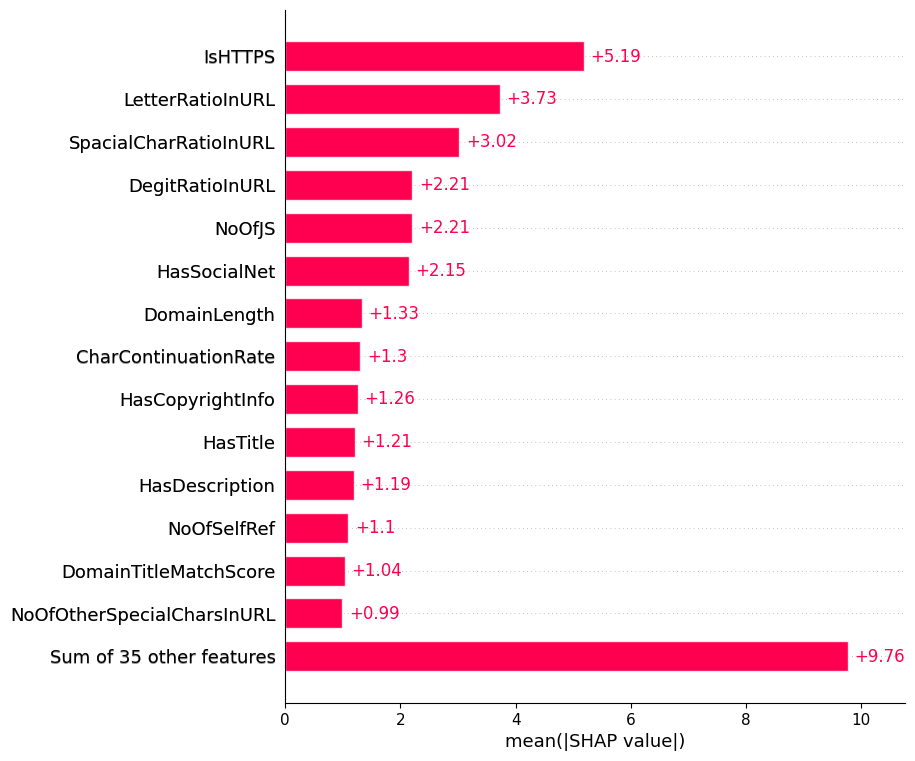

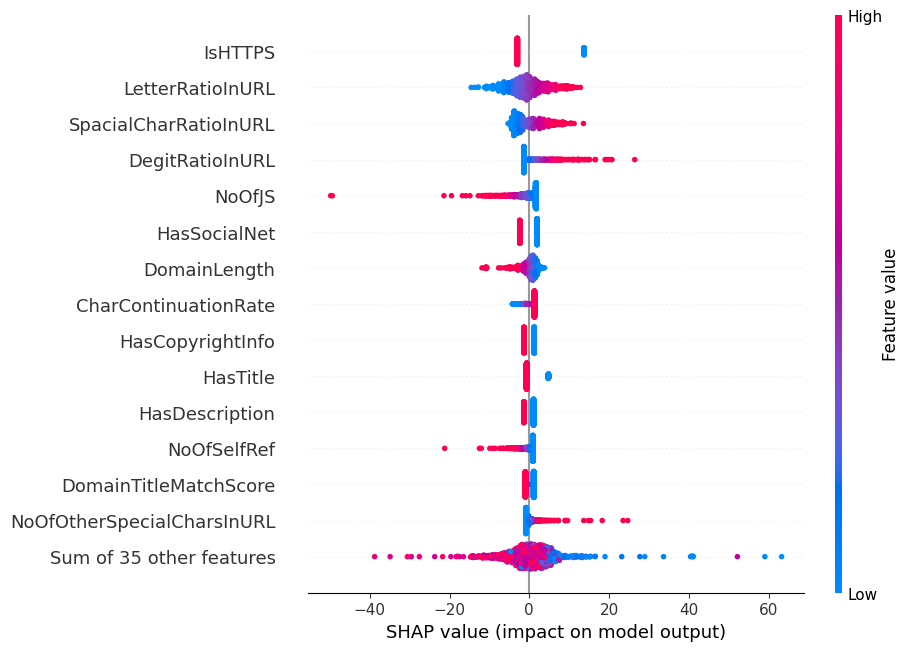

In [ ]:
# Computing SHAP Values and Global Importance Plots (1,000 Test URLs)
X_test_sample = X_test_scaled.iloc[:1000]

explainer = shap.LinearExplainer(model_l2, X_train_scaled)
shap_values = explainer(X_test_sample)

# 1. Global Mean Absolute SHAP Importance (Bar Plot)
shap.plots.bar(shap_values, max_display=15)

# 2. Global Directional Impact (Beeswarm Plot)
shap.plots.beeswarm(shap_values, max_display=15)

---
### 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)

We locate the first **True Positive (TP)**, **True Negative (TN)**, and **False Positive (FP — False Alarm)** in our 1,000-URL test sample and inspect their local SHAP Waterfall plots (`max_display=10`), passing unscaled `X_test` values in `data=` so SOC analysts can read actual URL metrics.

### Exercise 9

=== CASE 1: TRUE POSITIVE (Confirmed Phishing Attack Caught) (Sample Index=2) | True Label=1 | P(Phishing)=99.99% ===


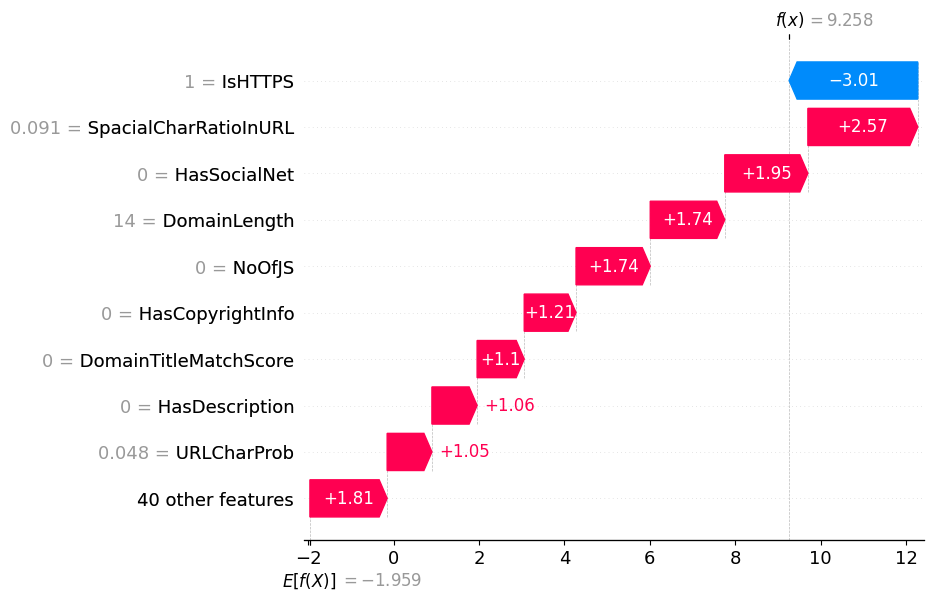

=== CASE 2: TRUE NEGATIVE (Legitimate Traffic Correctly Cleared) (Sample Index=0) | True Label=0 | P(Phishing)=0.00% ===


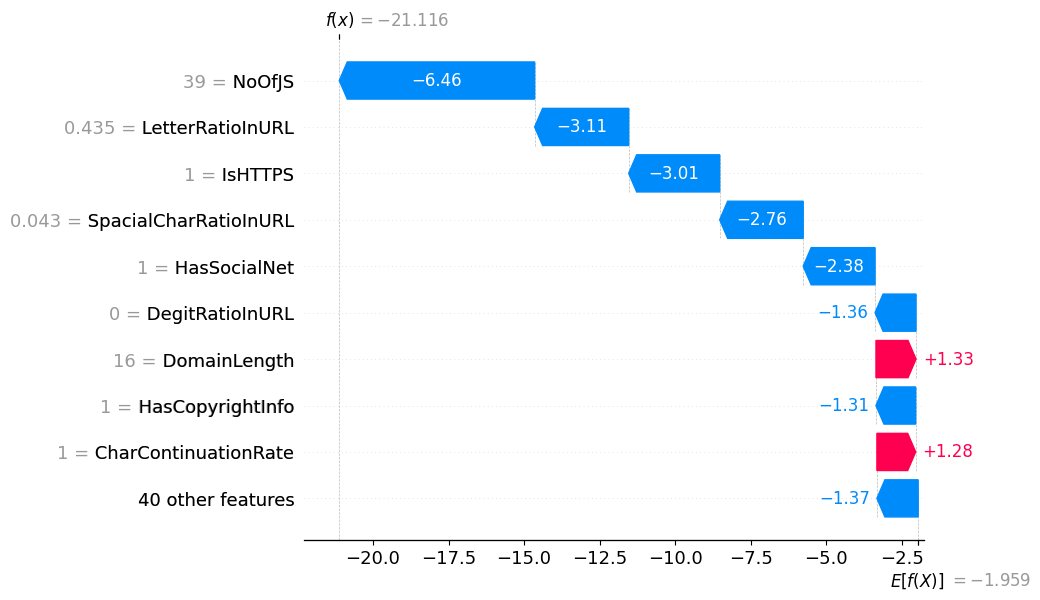

=== CASE 3: FALSE POSITIVE (Legitimate Site Wrongly Flagged — False Alarm) (Sample Index=330) | True Label=0 | P(Phishing)=31.58% ===


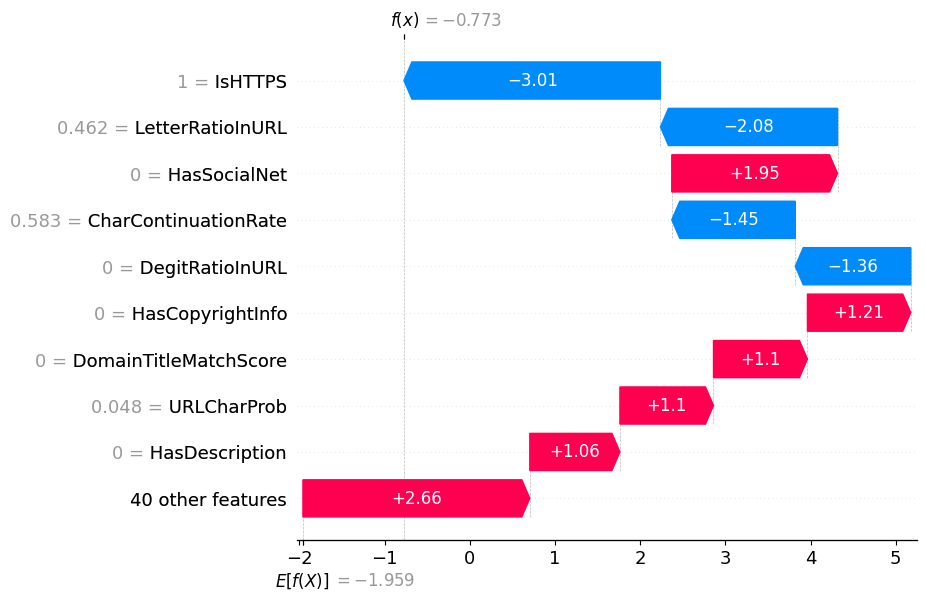

In [ ]:
# Local SOC Triage of TP, TN, and FP Cases with SHAP Waterfall
y_test_sample = y_test.iloc[:1000].values
y_prob_sample = model_l2.predict_proba(X_test_sample)[:, 1]
y_pred_sample = (y_prob_sample >= 0.50).astype(int)

tp_idx = int(np.where((y_test_sample == 1) & (y_pred_sample == 1))[0][0])
tn_idx = int(np.where((y_test_sample == 0) & (y_pred_sample == 0))[0][0])
fp_candidates = np.where((y_test_sample == 0) & (y_pred_sample == 1))[0]

fp_idx = int(fp_candidates[0]) if len(fp_candidates) > 0 else int(np.argmax(y_prob_sample * (y_test_sample == 0)))

def plot_soc_waterfall(idx, case_title):
    print(f"=== {case_title} (Sample Index={idx}) | True Label={y_test_sample[idx]} | P(Phishing)={y_prob_sample[idx]*100:.2f}% ===")
    local_exp = shap.Explanation(
        values=shap_values.values[idx],
        base_values=float(np.ravel(shap_values.base_values)[idx]),
        data=X_test.iloc[idx].values, # Unscaled values for human analyst readability
        feature_names=X.columns
    )
    shap.plots.waterfall(local_exp, max_display=10)

plot_soc_waterfall(tp_idx, "CASE 1: TRUE POSITIVE (Confirmed Phishing Attack Caught)")
plot_soc_waterfall(tn_idx, "CASE 2: TRUE NEGATIVE (Legitimate Traffic Correctly Cleared)")
plot_soc_waterfall(fp_idx, "CASE 3: FALSE POSITIVE (Legitimate Site Wrongly Flagged — False Alarm)")

---
### 5.3 Operational Decision Threshold Tuning ($\tau \in \{0.20, 0.50, 0.85\}$) (Exercise 10)

We evaluate `model_l2` (`M3`) on the full test set across three operational decision thresholds:
* **$\tau = 0.20$ (Threat Hunting Mode):** Maximizes Recall to catch stealthy phishing campaigns.
* **$\tau = 0.50$ (Default Mode):** Balanced threshold.
* **$\tau = 0.85$ (Automated Firewall Blocking Mode):** Maximizes Precision and minimizes False Positives to prevent blocking legitimate business traffic.

### Exercise 10

In [ ]:
# Comparing Operational Decision Thresholds (0.20, 0.50, 0.85)
y_prob_full = model_l2.predict_proba(X_test_scaled)[:, 1]
thresholds = [0.20, 0.50, 0.85]
threshold_records = []

for tau in thresholds:
    y_pred_tau = (y_prob_full >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tau).ravel()

    threshold_records.append({
        "Threshold (tau)": tau,
        "SOC Operational Mode": "Threat Hunting" if tau == 0.20 else ("Default" if tau == 0.50 else "Automated Blocking"),
        "Precision": round(precision_score(y_test, y_pred_tau), 4),
        "Recall (TPR)": round(recall_score(y_test, y_pred_tau), 4),
        "F1-Score": round(f1_score(y_test, y_pred_tau), 4),
        "True Positives (TP)": int(tp),
        "True Negatives (TN)": int(tn),
        "False Positives (FP)": int(fp),
        "False Negatives (FN)": int(fn)
    })

threshold_df = pd.DataFrame(threshold_records)
display(threshold_df)

,Threshold (tau),SOC Operational Mode,Precision,Recall (TPR),F1-Score,True Positives (TP),True Negatives (TN),False Positives (FP),False Negatives (FN)
0,0.20,Threat Hunting,0.9988,0.9994,0.9991,25221,33682,31,15
1,0.50,Default,0.9996,0.9989,0.9992,25208,33703,10,28
2,0.85,Automated Blocking,1.0000,0.9975,0.9987,25172,33713,0,64


---
### 💡 Part 4 Reflection Questions —

1. **What is the mathematical difference between inspecting a global weight $w_j$ and looking at a local SHAP value $\phi_j(x)$ for a specific URL?**
   * **Answer:** A global weight \(w_j\) represents the overall influence of a feature in the Logistic Regression model. A local SHAP value \(\phi_j(x)\) explains how much that feature contributes to the prediction of one specific URL.

2. **On your False Positive (FP) Waterfall plot, which 2 or 3 features misled the model and caused this false alarm?**
   * **Answer:** Identify the features with the largest positive SHAP values in your FP waterfall plot. These features increased the predicted phishing probability and caused the legitimate URL to be incorrectly classified as phishing.

3. **Why would a SOC deploy $\tau = 0.85$ for automated DNS/firewall blocking while routing URLs with $0.20 \le P(\text{Phishing}) < 0.85$ to a human analyst queue?**
   * **Answer:** A high threshold (0.85) reduces false positives, preventing legitimate websites from being blocked automatically. URLs with intermediate probabilities are sent to human analysts for verification, balancing security and usability.

---
## 6 - Conclusion & SOC Engineering Synthesis (Deliverable Solution)

> ### 🛡️ SOC Engineering Synthesis Report
> 1. **Hyperparameter & Sparsity Trade-Off:**

> 2. **Global Interpretability (Odds Ratios & SHAP):**

> 3. **SOC Alert Triage & Dual-Threshold Policy:**
  * *False Positive Triage Note (3 sentences):*

  * *Recommended Threshold Policy:*

 ### 🛡️ SOC Engineering Synthesis Report
 
 1. **Hyperparameter & Sparsity Trade-Off:**

L1 regularization eliminated 24 features while the F1-Score decreased only slightly, from 0.99925 (M3) to 0.99821 (M4). This produces a simpler and more efficient model with almost the same detection performance, making it suitable for real-time security applications.

2. **Global Interpretability (Odds Ratios & SHAP):**

Logistic Regression weights and odds ratios show how each feature influences phishing predictions. SHAP values provide additional explanations by showing each feature's contribution to individual predictions. Together, they improve model transparency and help security analysts understand suspicious URLs.

3. **SOC Alert Triage & Dual-Threshold Policy:**

False Positive Triage Note (3 sentences):

The False Positive case represents a legitimate website incorrectly classified as phishing. The SHAP waterfall plot helps identify which features contributed most to this incorrect prediction. A SOC analyst should investigate the URL and verify its legitimacy before taking action.

Recommended Threshold Policy:
- P(Phishing) below 0.20: Treat as low risk and allow access.
- 0.20 ≤ P(Phishing) < 0.85: Send an alert to the SOC analyst for manual investigation.
- P(Phishing) ≥ 0.85: Automatically block the URL, subject to security policy